# Density estimation and anomaly detection: scores, decisions, and guarantees

## 1. Introduction and learning objectives

A density model describes where observations concentrate in specified coordinates. An anomaly detector makes a decision relative to a declared reference population and an operational definition of unusual. These are different tasks. A large likelihood does not establish that an input is useful, safe, correctly labeled or even representative of most of a high-dimensional distribution's probability mass.

Derive a normalized Gaussian kernel density estimate (KDE), implement stable log densities and a manual bandwidth derivative, select bandwidth without calibration leakage, and turn a frozen score into a finite-sample false-alarm procedure. Compare a Gaussian baseline and KDE under matched information boundaries. Investigate separately what changes when fitting data are contaminated, calibration data are contaminated, or the nominal population shifts. The central habit is to state exactly which randomness and assumptions support a claim before reporting a number.

**Prerequisites:** Stage 00 probability, matrix calculus and numerical computing; Stage 01 validation, metrics and uncertainty. The [mixture chapter](gaussian-mixtures-and-em.ipynb) supplies Gaussian/log-sum-exp intuition, and [PCA/SVD](pca-and-svd.ipynb) supplies the distinction between invertible scaling and dimension reduction. Necessary formulas are restated here. Use NumPy and Matplotlib only; there is no download or GPU requirement.

## 2. Prerequisites and mathematical foundations

Write training rows as $X\in\mathbb R^{n\times d}$ and query rows as $Q\in\mathbb R^{m\times d}$. A continuous density $p(x)$ is nonnegative and integrates to one; $p(x)$ is not $P(X=x)$, which is zero for an absolutely continuous distribution. In one dimension, a sufficiently small interval has probability approximately $p(x)\Delta x$. Density has reciprocal-volume units and can exceed one.

For an invertible transformation $z=A^{-1}(x-b)$, density in the original coordinates is $p_X(x)=p_Z(z)/|\det A|$. Thus $\log p_X=\log p_Z-\log|\det A|$. A fixed positive diagonal rescaling changes all log densities by a constant if the same distribution is transformed correctly. It preserves within-population score rankings. Re-fitting a fixed isotropic kernel in arbitrary new raw units is a different model, not a change-of-variables identity. A projection from $d$ to $k<d$ dimensions is not invertible; its marginal density is not an ambient $d$-dimensional density.

Define a score $s(x)$ so **larger means more unusual**. The negative fitted log density $-\log\hat p(x)$ is one choice. A Gaussian's squared Mahalanobis radius has the same ranking as its negative log density for that fixed Gaussian. Neither score is a probability of being anomalous. A decision also needs a threshold and a reference population. Detection power depends on which alternative inputs matter; no unlabeled nominal sample determines every meaningful alternative.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 03.05.01 — Separate density, unusualness, and an operational decision

**Type:** Conceptual · **Answer:** Markdown

Explain why density can exceed one, why a density height is not an anomaly probability, and why a high-likelihood input can still be an operational failure. State a nominal population and an alternative of interest for a concrete application. Describe what a false positive means in that application.

**Expected outcome:** correctly named probability events, units, a score direction, and a decision whose meaning depends on the declared population.

**Your response to Exercise 03.05.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.01**

An interval probability includes its width. An outlier p-value concerns compatibility with a null population, not a posterior class probability.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.01**

A narrow continuous distribution can place considerable probability in a small volume, so its density height can exceed one while its integral remains one. Density is measured relative to coordinates; the probability of an exact point is still zero. Negative log density ranks inputs according to a model, whereas a posterior anomaly probability would additionally require an alternative model and prior frequency. For a sensor, nominal might mean measurements under a specified operating range, with faults as the alternative; flagging a healthy measurement is a false positive. An unfamiliar operating regime can be statistically unusual without being a fault, and a faulty input can resemble the fitted nominal population. A well-calibrated false-alarm procedure does not resolve that semantic ambiguity or guarantee power.

</details>

## 3. Theoretical development and worked examples

### A constrained Gaussian baseline

For nominal training rows, the Gaussian maximum-likelihood mean is $\bar x=n^{-1}\sum_i x_i$ and covariance is $S=n^{-1}\sum_i(x_i-\bar x)(x_i-\bar x)^T$. This chapter deliberately uses $1/n$, not the unbiased covariance convention $1/(n-1)$. If $S=U\operatorname{diag}(\lambda_j)U^T$, impose a fixed variance floor $\epsilon>0$ and use $\hat\Sigma=U\operatorname{diag}(\max(\lambda_j,\epsilon))U^T$. This is the constrained Gaussian likelihood optimum for $\Sigma\succeq\epsilon I$, not arbitrary repeated diagonal jitter. The floor is in training-standardized units and is fixed before evaluation.

For $L L^T=\hat\Sigma$, solve $Lr=x-\bar x$ and evaluate
$$\log\hat p(x)=-\tfrac12\left[d\log(2\pi)+2\sum_j\log L_{jj}+\|r\|^2\right].$$
Avoid a raw inverse and determinant. The Gaussian can express one ellipsoidal concentration region. A multimodal nominal distribution can have a low-density gap between modes that this baseline treats as central. That is a modeling limitation, not a factorization error.

### Gaussian KDE: normalize first, then calculate stably

Let $K(u)=(2\pi)^{-d/2}\exp(-\|u\|^2/2)$ and $h>0$ be a bandwidth. A KDE is an equally weighted mixture with one kernel at each training row:
$$\hat p_h(q)=\frac{1}{n h^d}\sum_{i=1}^n K\!\left(\frac{q-x_i}{h}\right).$$
Each term integrates to one after substitution $u=(q-x_i)/h$, whose volume Jacobian is $h^d$. The factor is $h^{-d}$, not merely $h^{-1}$ in every dimension. The scalar $h$ is a standard deviation in the working coordinates; each Gaussian kernel has covariance $h^2 I$. Small $h$ produces narrow peaks; large $h$ smooths away local structure. Smoothness and normalization do not establish that the fitted density is accurate.

Set $a_i=-\|q-x_i\|^2/(2h^2)$ and $c=\max_i a_i$. Then
$$\log\hat p_h(q)=-\log n-d\log h-\tfrac d2\log(2\pi)+c+\log\sum_i e^{a_i-c}.$$
Subtracting $c$ prevents all kernel weights from underflowing simultaneously when raw densities are tiny. It does not prevent overflow in distances or rescue an invalid bandwidth. Work in query blocks and accumulate one feature's squared differences at a time. This needs $O(Bn)$ distance scratch, rather than an $m\times n\times d$ difference tensor. Total work is still $O(mnd)$ and retaining all training rows still costs $O(nd)$.

### Differentiate the declared validation objective

Write $\ell=\log h$, $r_i^2=\|q-x_i\|^2/h^2$ and normalized kernel weights $w_i=e^{a_i}/\sum_j e^{a_j}$. Holding training and query coordinates fixed,
$$\frac{\partial\log\hat p_h(q)}{\partial\ell}=-d+\sum_i w_i r_i^2.$$
For **mean negative log density** $J(\ell)=-m^{-1}\sum_{q\in V}\log\hat p_{e^\ell}(q)$,
$$\frac{\partial J}{\partial\ell}=d-\frac1m\sum_{q\in V}\sum_i w_i(q)r_i^2(q).$$
There is one observation average. Do not divide the dimension term by $m$ again. The derivation checks a differentiable scoring computation, not the derivative of a discrete grid selector or the fitted preprocessing. Finite differences must freeze the same training/query arrays and vary only $\ell$.

**Hand case:** training points $(-1,1)$, query zero and $h=1$ give density $e^{-1/2}/\sqrt{2\pi}\approx.24197072$, negative log density $(1+\log(2\pi))/2$, and log-bandwidth derivative zero. At $h=1/2$, density is $2e^{-2}/\sqrt{2\pi}\approx.10798193$ and the negative-log-density derivative is $1-4=-3$. The fitted single Gaussian has mean zero and ML variance one, so its density at zero is $1/\sqrt{2\pi}\approx.39894228$. It puts more density at the gap than the two-kernel estimate does.

### Choose a bandwidth with an information boundary

Fit centering/scaling on training rows only. For a declared finite candidate grid, compute each candidate's mean negative log density on a separate nominal validation set, select the first minimum in the declared grid order, and retain all candidate losses. Here the final score keeps that training fit; it does not refit on validation rows. Calibration is a later, untouched split. Validation log likelihood is a density-model selection criterion; it need not maximize detection of a particular fault class.

Training self-likelihood is unsuitable: at every training point the self-kernel contributes $(n h^d)^{-1}(2\pi)^{-d/2}$, so average training log density diverges to $+\infty$ as $h\to0$. Leave-one-out (LOO) likelihood removes only the indexed self-term and divides by $n-1$. It needs $n>1$; duplicate rows still contribute kernels to one another. LOO can be a valid selection design for IID rows, but does not repair entity leakage or duplicated measurements of one underlying item. This delivery uses an independent validation split instead of implementing a second selector.

### Calibrate a frozen score by its rank

After all fitting, preprocessing and score/hyperparameter choices, freeze $s$. Let $S_1,\ldots,S_c$ be scores of nominal calibration rows and $S_*$ a new nominal score, exchangeable conditional on the fitted score. IID fresh rows are a sufficient condition. Define the conservative rank p-value
$$p_* = \frac{1+\#\{i:S_i\ge S_*\}}{c+1}.$$
Flag when $p_*\le\alpha$, for a predeclared $0<\alpha<1$. The plus one includes the new score itself; using $>$ inside the count would mishandle ties. With distinct scores, the new observation's rank among $c+1$ exchangeable observations is uniform, so at most $\lfloor\alpha(c+1)\rfloor$ ranks are rejected. With ties, counting all equal scores as at least as extreme makes the rule conservative.

Equivalently let $k=\lceil(c+1)(1-\alpha)\rceil$. Use the **$k$th smallest calibration score**, with one-based indexing, and flag strictly above it. If $k>c$, use $+\infty$ and flag nothing. Smallest possible p-value is $1/(c+1)$. The guarantee is
$$P(\text{flag a new nominal observation})\le\frac{\lfloor\alpha(c+1)\rfloor}{c+1}\le\alpha,$$
marginal over calibration and the new nominal observation, conditional on the independent training/selection fit. It is not a guarantee for every realized calibration set, subgroup, time period or alternative input. It does not control the probability of at least one false alarm in a long stream or a false-discovery proportion. Reusing calibration outcomes to choose a score or threshold requires a different analysis.

Use exact integer rank arithmetic. The reference interprets an alpha string or a scalar's decimal representation as a rational value, using the standard-library `Fraction`. Prefer a declared string such as `'0.1'`. A float expression such as `0.1+0.2` has a different decimal representation and therefore a different declared value; no hidden epsilon adjusts it. A generic quantile API's interpolation convention is not a substitute for specifying this order statistic.

### Exercise 03.05.02 — Derive normalization and the bandwidth derivative

**Type:** Mathematical · **Answer:** Markdown

Prove that the multivariate KDE integrates to one. Derive the gradient of the mean validation negative log density with respect to log bandwidth, including the derivative of the normalizer. State which quantities are held fixed and the time/scratch complexity of featurewise blocked scoring.

**Expected outcome:** $h^{-d}$, one observation average, derivative $d-\operatorname{mean}_q\sum_i w_i r_i^2$, and a bounded scratch claim that does not imply constant total work.

**Your response to Exercise 03.05.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.02**

The substitution contributes $h^d$ volume. Differentiating $-r_i^2/2$ with respect to log bandwidth gives $r_i^2$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.02**

For each kernel substitute $u=(q-x_i)/h$; its $h^d$ volume cancels the denominator. Averaging normalized kernels preserves total mass one. Differentiating the log normalizer gives $-d$, and differentiating the log sum gives the normalized weighted average of squared standardized distances. Negating and averaging over the $m$ validation rows gives $d-m^{-1}\sum_q\sum_i w_i r_i^2$. Training rows, query rows, and training-fitted preprocessing stay fixed. Blocks of at most $B$ queries use $O(Bn)$ pairwise scratch and $O(nd+m)$ retained inputs/outputs, while arithmetic remains $O(mnd)$. An implementation that forms a three-dimensional difference tensor loses that scratch bound.

</details>

### Exercise 03.05.03 — Audit a hand density and a finite rank decision

**Type:** Numerical · **Answer:** Markdown

Calculate both KDE values and derivatives in the hand case. For calibration scores one through nine and $\alpha=.35$, find the exact threshold, p-values and decisions for queries $7,7.1,9,10$. Repeat the decision question at $\alpha=.05$.

**Expected outcome:** normalized numerical densities, correct gradient signs, one-based threshold seven, conservative ties, and no rejection below the rank resolution.

**Your response to Exercise 03.05.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.03**

For $c=9$, p-value numerators are integers out of ten. The score equal to the threshold is retained.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.03**

At bandwidth one, each kernel density at zero is $e^{-1/2}/\sqrt{2\pi}$, so their average is the same number and the NLL derivative is zero. At bandwidth one half, the density is $2e^{-2}/\sqrt{2\pi}$ and derivative $-3$: increasing bandwidth initially lowers NLL. For nine calibration scores and alpha $.35$, three ranks out of ten are rejectable; $k=10-3=7$, giving threshold seven. P-values are $.4,.3,.2,.1$, so only the last three queries are flagged. At alpha $.05$, not even the smallest possible p-value $.1$ is rejectable; the threshold is infinite. Replacing the strict threshold comparison with greater-than-or-equal would wrongly flag ties.

</details>

## 4. Guided exercises

### Exercise 03.05.04 — Fit training-only coordinates and the Gaussian baseline

**Type:** Programming · **Answer:** Code

Implement finite row-matrix checks, training-only standardization, application to new rows, and the fixed-floor Gaussian likelihood. Use covariance divisor $n$, an eigenvalue floor, Cholesky solves, and copied fitted arrays. A constant training coordinate uses scale one; a nonconstant coordinate whose scale vanishes numerically is an arithmetic failure. Cap fitting at 2,000 rows and 16 features, scoring at 20,000 rows.

**Expected outcome:** correct one-row/constant/rank-deficient behavior, independent small Gaussian likelihood checks, and no validation-dependent preprocessing.

In [ ]:
# Your code for Exercise 03.05.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.04**

Fit the coordinate transform once. An eigenvalue floor constrains variances along covariance eigenvectors; adding the floor to every eigenvalue is a different estimator.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.04**

The helpers below are local to this notebook. Constant columns are retained rather than discarded, so the transform remains invertible. Their scale-one convention and covariance floor do not establish that the true population is continuous or Gaussian. Unsupported shapes and nonfinite inputs fail explicitly; arithmetic overflow is not converted into a plausible density.

~~~python
def density_rows(values, name, limit, empty=False):
    x = np.asarray(values, dtype=float)
    if x.ndim != 2 or not 1 <= x.shape[1] <= 16 or x.shape[0] > limit or (not empty and len(x) == 0) or not np.isfinite(x).all():
        raise ValueError(name+' requires finite rows, 1..16 features, within the row limit')
    return x

def density_positive(value, name):
    a = np.asarray(value, dtype=float)
    if isinstance(value,(bool,np.bool_)) or a.ndim != 0 or not np.isfinite(a) or a <= 0:
        raise ValueError(name+' must be a finite positive scalar')
    return float(a)

def density_block_size(value):
    if isinstance(value,(bool,np.bool_)) or not isinstance(value,(int,np.integer)) or not 1 <= value <= 256:
        raise ValueError('query block must be an integer in 1..256')
    return int(value)

def fit_density_coordinates(train):
    x = density_rows(train,'training',2000)
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        mean = x.mean(axis=0)
        centered = x-mean
        scale = np.sqrt(np.mean(centered**2,axis=0))
    constant = np.all(x == x[0],axis=0)
    if np.any((scale <= 0) & ~constant) or not np.isfinite(scale).all():
        raise FloatingPointError('nonconstant coordinate lost its scale')
    scale[constant] = 1.
    return dict(mean=mean.copy(),scale=scale.copy())

def apply_density_coordinates(values, coordinates):
    x = density_rows(values,'queries',20000,empty=True)
    mean = np.asarray(coordinates['mean'],dtype=float)
    scale = np.asarray(coordinates['scale'],dtype=float)
    if mean.shape != (x.shape[1],) or scale.shape != mean.shape or not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale <= 0):
        raise ValueError('invalid fitted coordinates')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        return (x-mean)/scale

def fit_density_gaussian(train, variance_floor=.02):
    x = density_rows(train,'Gaussian training',2000)
    floor = density_positive(variance_floor,'variance floor')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        mean = x.mean(axis=0); centered = x-mean
        covariance = centered.T@centered/len(x)
        eigenvalues, axes = np.linalg.eigh(covariance)
        covariance = (axes*np.maximum(eigenvalues,floor))@axes.T
        chol = np.linalg.cholesky(covariance)
    if not np.isfinite(chol).all():
        raise FloatingPointError('nonfinite Gaussian factor')
    return dict(mean=mean.copy(),covariance=covariance.copy(),chol=chol.copy(),variance_floor=floor)

def gaussian_density_logpdf(queries, model):
    q = density_rows(queries,'Gaussian queries',20000,empty=True)
    mean = np.asarray(model['mean'],dtype=float); chol = np.asarray(model['chol'],dtype=float)
    d = q.shape[1]
    if mean.shape != (d,) or chol.shape != (d,d) or not np.isfinite(mean).all() or not np.isfinite(chol).all() or np.any(np.diag(chol) <= 0) or not np.array_equal(chol,np.tril(chol)):
        raise ValueError('invalid Gaussian mean or Cholesky factor')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        residual = np.linalg.solve(chol,(q-mean).T)
        result = -.5*(d*np.log(2*np.pi)+2*np.log(np.diag(chol)).sum()+(residual**2).sum(axis=0))
    if not np.isfinite(result).all():
        raise FloatingPointError('Gaussian score exceeds arithmetic range')
    return result
~~~

</details>

### Exercise 03.05.05 — Implement blocked stable KDE and its manual derivative

**Type:** Programming · **Answer:** Code

Implement log scoring and the mean NLL/log-bandwidth gradient. Accumulate featurewise squared differences in query blocks; never allocate a query-by-training-by-feature tensor. Reject invalid bandwidths, row budgets and block sizes. Preserve a finite log score when direct Gaussian exponentiation underflows. Show failures for distances that exceed arithmetic range rather than clipping them.

**Expected outcome:** scalar-mixture agreement, normalization checks, finite differences at fixed arrays, and identical values across block sizes, including empty query scoring.

In [ ]:
# Your code for Exercise 03.05.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.05**

After subtracting the largest log weight, at least one weight is one. Reuse normalized weights to obtain the weighted squared radius.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.05**

This snippet depends on the validation helpers in Exercise 03.05.04. The distance array and its weights have only two axes. Log scoring remains finite for representable large distances even if every raw kernel density underflows; arbitrary input magnitudes are still outside safe floating-point range. The NLL objective requires at least one validation row, although pure scoring accepts an empty query matrix with the correct feature count.

~~~python
def kde_log_statistics(train, queries, bandwidth, block=64):
    x = density_rows(train,'KDE training',2000)
    q = density_rows(queries,'KDE queries',20000,empty=True)
    if x.shape[1] != q.shape[1]:
        raise ValueError('training/query feature counts differ')
    h = density_positive(bandwidth,'bandwidth'); block = density_block_size(block)
    logs = np.empty(len(q)); weighted_radius = np.empty(len(q)); d = x.shape[1]
    with np.errstate(over='raise',invalid='raise',divide='raise',under='ignore'):
        normalizer = np.log(len(x))+d*np.log(h)+.5*d*np.log(2*np.pi)
        for start in range(0,len(q),block):
            end = min(start+block,len(q))
            squared = np.zeros((end-start,len(x)))
            for j in range(d):
                difference = (q[start:end,j,None]-x[None,:,j])/h
                squared += difference*difference
            largest = (-.5*squared).max(axis=1)
            weights = np.exp(-.5*squared-largest[:,None])
            total = weights.sum(axis=1)
            logs[start:end] = largest+np.log(total)-normalizer
            weighted_radius[start:end] = (weights*squared).sum(axis=1)/total
    if not np.isfinite(logs).all() or not np.isfinite(weighted_radius).all():
        raise FloatingPointError('KDE arithmetic range exceeded')
    return logs,weighted_radius

def kde_density_logpdf(train, queries, bandwidth, block=64):
    return kde_log_statistics(train,queries,bandwidth,block)[0]

def kde_nll_log_bandwidth_gradient(train, validation, bandwidth, block=64):
    q = density_rows(validation,'validation',20000)
    logs,radius = kde_log_statistics(train,q,bandwidth,block)
    return float(-logs.mean()),float(q.shape[1]-radius.mean())

hand_train = np.array([[-1.],[1.]])
for h in (1.,.5):
    loss,gradient = kde_nll_log_bandwidth_gradient(hand_train,[[0.]],h)
    print('hand bandwidth, density, mean NLL, derivative',h,np.exp(-loss),loss,gradient)
~~~

</details>

### Exercise 03.05.06 — Select bandwidth without touching calibration

**Type:** Programming · **Answer:** Code

Implement the fixed candidate-grid selector and a two-model fitting function. Fit standardization on training only; score a separate validation set in the original density units. Keep every candidate's validation loss and derivative, select the first minimum, and keep the original training fit. The Gaussian floor is fixed at .02 and is not another hidden tuned grid. Allow at most twelve declared bandwidth candidates.

**Expected outcome:** reproducible selection, copied fitted training arrays, Gaussian/KDE scores in comparable coordinates, and no calibration or final-data arguments in fitting functions.

In [ ]:
# Your code for Exercise 03.05.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.06**

The Jacobian contributes the same constant to all validation losses but still matters for reporting density units. Returning an audit table prevents unsuccessful or inferior candidates from disappearing.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.06**

This snippet depends on Exercises 03.05.04–05. Provenance cannot be inferred from equal row values: genuinely independent samples can coincide, and duplicate entities can have different feature values. The caller must create independent splits or an appropriate grouped design. The API prevents accidental direct calibration arguments but cannot prove that the supplied arrays have honest provenance. No score method is selected using anomaly labels.

~~~python
def select_density_bandwidth(train, validation, candidates, block=64):
    x = density_rows(train,'selector training',2000)
    v = density_rows(validation,'selector validation',20000)
    candidates = np.asarray(candidates,dtype=float)
    if candidates.ndim != 1 or not 1 <= len(candidates) <= 12 or not np.isfinite(candidates).all() or np.any(candidates <= 0):
        raise ValueError('declare 1..12 finite positive bandwidths')
    table = []
    for h in candidates:
        loss,gradient = kde_nll_log_bandwidth_gradient(x,v,float(h),block)
        table.append(dict(bandwidth=float(h),validation_nll=loss,log_bandwidth_gradient=gradient))
    index = int(np.argmin([row['validation_nll'] for row in table]))
    return dict(train=x.copy(),bandwidth=table[index]['bandwidth'],selected_index=index,validation_table=table)

def fit_density_models(train, validation, candidates=(.15,.3,.5,.8,1.2)):
    coordinates = fit_density_coordinates(train)
    x = apply_density_coordinates(train,coordinates)
    v = apply_density_coordinates(validation,coordinates)
    gaussian = fit_density_gaussian(x,.02)
    kde = select_density_bandwidth(x,v,candidates)
    jacobian = float(np.log(coordinates['scale']).sum())
    gaussian_validation_nll = float(-gaussian_density_logpdf(v,gaussian).mean()+jacobian)
    for row in kde['validation_table']:
        row['validation_nll_original_units'] = row['validation_nll']+jacobian
    return dict(coordinates=coordinates,gaussian=gaussian,kde=kde,
                gaussian_validation_nll=gaussian_validation_nll,log_volume=jacobian)

def score_density_models(fitted, queries):
    q = apply_density_coordinates(queries,fitted['coordinates'])
    kde = fitted['kde']; constant = fitted['log_volume']
    return dict(gaussian=-gaussian_density_logpdf(q,fitted['gaussian'])+constant,
                kde=-kde_density_logpdf(kde['train'],q,kde['bandwidth'])+constant)
~~~

</details>

## 5. Implementation challenges

### Exercise 03.05.07 — Prove the finite-rank rule and identify its limits

**Type:** Mathematical · **Answer:** Markdown

Prove the rejection bound for distinct exchangeable scores and explain why inclusive extreme counts handle ties conservatively. Establish equivalence to the strict order-statistic threshold, including alpha below rank resolution. State what must be independent of calibration and what the probability averages over.

**Expected outcome:** a finite-sample rank argument, an explicit infinite-threshold case, and no unsupported conditional, power or multiple-testing guarantee.

**Your response to Exercise 03.05.07**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.07**

Let $a=\lfloor\alpha(c+1)\rfloor$. With distinct scores, only the largest $a$ of $c+1$ ranks can have p-value at most alpha.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.07**

Conditional on the independently trained/selected score, exchangeability makes each distinct rank of the new nominal observation equally likely. At most $a$ ranks have at most $a-1$ calibration scores above them, giving rejection probability $a/(c+1)$. With ties, the inclusive count assigns the least favorable extreme rank in its tied group, so rejection cannot become more frequent. The one-based threshold index is $k=c+1-a$. If $a=0$, this is $c+1$ and the threshold is infinite. Otherwise a query strictly above the $k$th calibration score has at most $a-1$ calibration scores at least as large; a query at or below it has at least $a$ such scores. The guarantee averages over calibration and the next nominal row, not over a fixed realized threshold alone. Score selection, preprocessing and any bandwidth search must precede this independent calibration split. There is no lower bound on anomaly power and no stream-wise family error guarantee.

</details>

### Exercise 03.05.08 — Implement exact ranks, conservative ties, and explicit alpha

**Type:** Programming · **Answer:** Code

Implement a threshold and p-value decision function using the specified decimal-rational alpha policy. Return p-values, integer numerators, decisions, threshold and calibration size. Sort/search calibration scores instead of allocating a calibration-by-query comparison matrix. Reject empty/nonfinite calibration, malformed score vectors and invalid alpha. Do not use an interpolating quantile routine.

**Expected outcome:** exact small-rank enumeration, p-value/strict-threshold equivalence, ties retained, and the hand case without off-by-one rounding.

In [ ]:
# Your code for Exercise 03.05.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.08**

Compute the number of rejectable ranks using integer numerator/denominator arithmetic. `searchsorted(..., side='left')` counts calibration scores strictly below the query.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.08**

This snippet is independent of the density implementations; only the score direction matters. It accepts alpha strings, standard numeric scalars and `Fraction` values. A decimal string makes the intended level explicit. Float p-values are convenient for reporting, but rejection uses integer numerators and the exact rational level; no rounded p-value decides an equality boundary.

~~~python
from fractions import Fraction

def density_alpha(value):
    if isinstance(value,(bool,np.bool_)) or not isinstance(value,(str,int,float,np.integer,np.floating,Fraction)):
        raise ValueError('alpha must specify a scalar decimal or rational level')
    try:
        level = Fraction(str(value))
    except (ValueError,ZeroDivisionError,OverflowError) as error:
        raise ValueError('invalid finite alpha') from error
    if not 0 < level < 1:
        raise ValueError('alpha must be strictly between zero and one')
    return level

def density_scores(values, name, empty=False):
    scores = np.asarray(values,dtype=float)
    if scores.ndim != 1 or len(scores) > 20000 or (not empty and len(scores) == 0) or not np.isfinite(scores).all():
        raise ValueError(name+' must be a finite vector within 20000 scores')
    return scores

def conformal_density_threshold(calibration_scores, alpha='0.1'):
    scores = density_scores(calibration_scores,'calibration')
    level = density_alpha(alpha); n = len(scores)
    allowed = level.numerator*(n+1)//level.denominator
    k = n+1-allowed
    threshold = np.inf if k > n else float(np.sort(scores)[k-1])
    return dict(threshold=threshold,k=k,n=n,rejectable_ranks=allowed,
                alpha_numerator=level.numerator,alpha_denominator=level.denominator)

def conformal_density_decisions(calibration_scores, query_scores, alpha='0.1'):
    calibration = density_scores(calibration_scores,'calibration')
    query = density_scores(query_scores,'queries',empty=True)
    rule = conformal_density_threshold(calibration,alpha)
    numerator = 1+len(calibration)-np.searchsorted(np.sort(calibration),query,side='left')
    flags = numerator <= rule['rejectable_ranks']
    if not np.array_equal(flags,query > rule['threshold']):
        raise ArithmeticError('rank/threshold decision disagreement')
    return dict(**rule,pvalue=numerator/(len(calibration)+1),numerator=numerator,flags=flags)

hand_rule = conformal_density_decisions(np.arange(1.,10.),[7.,7.1,9.,10.],'0.35')
print('hand threshold, p-values, flags',hand_rule['threshold'],hand_rule['pvalue'],hand_rule['flags'])
~~~

</details>

### Exercise 03.05.09 — Report detection rates without inventing certainty

**Type:** Programming · **Answer:** Code

For a nonempty Boolean vector of flags, return its count, rate and an approximate 95% Wilson interval. Explain why an interval across independent test rows, conditional on a frozen model and calibration set, does not describe variability from drawing a new calibration set. Keep nominal false-positive rates separate from anomaly-probe detection rates.

**Expected outcome:** sensible zero/all-flag intervals, explicit denominators and a conditional sampling interpretation rather than a second conformal guarantee.

In [ ]:
# Your code for Exercise 03.05.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.09**

For $\hat r=b/N$, Wilson's center is $(\hat r+z^2/(2N))/(1+z^2/N)$ and half-width is $z\sqrt{\hat r(1-\hat r)/N+z^2/(4N^2)}/(1+z^2/N)$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.09**

The following interval is an approximate binomial summary with $z=1.959963984540054$. It applies to independent evaluation rows from the stated population conditional on the fixed fitted detector. Shared calibration makes decisions dependent when averaged over new calibration sets; this interval does not account for that source of variation, training variability, subgroup selection or multiple comparisons. In a dependent time series, an IID binomial interval is not justified. A detection rate on an artificial alternative only describes that alternative.

~~~python
def density_flag_report(flags):
    a = np.asarray(flags)
    if a.dtype != np.bool_ or a.ndim != 1 or not 1 <= len(a) <= 20000:
        raise ValueError('a nonempty bounded Boolean flag vector is required')
    n = len(a); count = int(a.sum()); rate = count/n; z = 1.959963984540054
    denominator = 1+z*z/n
    center = (rate+z*z/(2*n))/denominator
    width = z*np.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/denominator
    lower = 0. if count == 0 else float(max(0.,center-width))
    upper = 1. if count == n else float(min(1.,center+width))
    return dict(n=n,flagged=count,rate=rate,approximate_95_interval=(lower,upper))
~~~

</details>

## 6. Experiments and visualizations

### See a model assumption before fitting it

The first panel below is an analytic population example, not a fitted learner implementation. Its two equally likely Gaussian components have centers $-2$ and $2$ and standard deviation $.45$. The moment-matched Gaussian has variance $4+.45^2$ and places substantial density in the gap. Whether that gap is a relevant anomaly depends on the application. The second panel describes a different issue: a 64-dimensional standard Gaussian has maximal point density at zero, but its radius is usually near eight. Radial probability includes a volume factor $r^{63}$. These are two distinct reasons not to read a point density as a complete anomaly judgment.

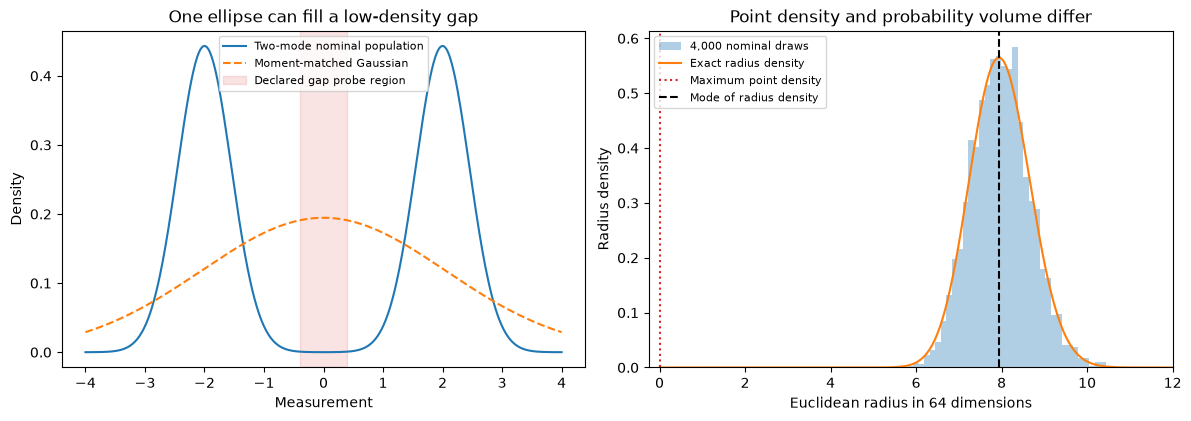

Population radial squared-norm mean and variance: 64 128
Observed squared-norm mean: 64.19685282031723


In [2]:
import math
grid = np.linspace(-4.,4.,500)
truth = .5*np.exp(-.5*((grid+2)/.45)**2)/(.45*np.sqrt(2*np.pi))+.5*np.exp(-.5*((grid-2)/.45)**2)/(.45*np.sqrt(2*np.pi))
moment_sd = np.sqrt(4+.45**2)
single = np.exp(-.5*(grid/moment_sd)**2)/(moment_sd*np.sqrt(2*np.pi))
radius = np.linspace(0.,12.,400)
radial = np.zeros_like(radius)
radial[1:] = np.exp((1-64/2)*np.log(2)-math.lgamma(64/2)+63*np.log(radius[1:])-.5*radius[1:]**2)
rng = np.random.default_rng(30501)
observed_radius = np.linalg.norm(rng.normal(size=(4000,64)),axis=1)
fig,axes = plt.subplots(1,2,figsize=(11.8,4.1),layout='constrained')
axes[0].plot(grid,truth,label='Two-mode nominal population')
axes[0].plot(grid,single,label='Moment-matched Gaussian',linestyle='--')
axes[0].axvspan(-.4,.4,alpha=.13,color='tab:red',label='Declared gap probe region')
axes[0].set(xlabel='Measurement',ylabel='Density',title='One ellipse can fill a low-density gap')
axes[0].legend(fontsize=8)
axes[1].hist(observed_radius,bins=36,density=True,alpha=.35,label='4,000 nominal draws')
axes[1].plot(radius,radial,label='Exact radius density')
axes[1].axvline(0.,color='tab:red',linestyle=':',label='Maximum point density')
axes[1].axvline(np.sqrt(63),color='black',linestyle='--',label='Mode of radius density')
axes[1].set(xlabel='Euclidean radius in 64 dimensions',ylabel='Radius density',title='Point density and probability volume differ',xlim=(-.25,12.))
axes[1].legend(fontsize=8)
plt.show()
print('Population radial squared-norm mean and variance:',64,128)
print('Observed squared-norm mean:',float(np.mean(observed_radius**2)))

### Exercise 03.05.10 — Compare matched detectors and three failure conditions

**Type:** Experimental · **Answer:** Code

Generate independent nominal training, validation, calibration and final evaluation sets. Use a two-mode population in two dimensions, a predeclared gap alternative, and a shifted population that remains operationally nominal. Compare Gaussian and validation-selected KDE with alpha .1 under three conditions: clean data, 20% training contamination, and 20% calibration contamination. Reuse final evaluation rows across methods for paired comparisons; keep their labels and scores out of fitting/selection. Retain all six method/condition records, all bandwidth candidates, thresholds, counts and conditional rate intervals. Do not announce a winner from repeated final-set tuning.

**Expected outcome:** a reproducible comparison that distinguishes nominal false alarms, gap detection, shift sensitivity and the different effects of contamination during fitting versus calibration.

In [ ]:
# Your code for Exercise 03.05.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.10**

Train contamination changes the score, but an independent clean calibration set can still calibrate that frozen score. Contaminated calibration changes the reference distribution underlying the rank guarantee.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.10**

This experiment depends on Exercises 03.05.04–06 and 03.05.08–09. Nominal rows are IID mixtures with independently drawn component assignments, not fixed per-component counts. The gap probe is deliberately chosen before fitting. It is not a universal model of every anomaly. A location shift of $(0,1.5)$ is declared operationally nominal to test robustness, although it changes the statistical population. That stress condition deliberately breaks calibration/test exchangeability.

There are 240 training rows, 160 validation rows, 199 calibration rows, 400 final nominal rows, 400 gap probes and 400 shifted nominal rows. The training-contaminated condition replaces the first 48 training rows with independent distant points; the calibration-contaminated condition replaces 40 calibration rows. Both replacements are design interventions, not assertions that contamination is IID nominal. The two fitted conditions each compare five bandwidths and one fixed-floor Gaussian. The clean fit is reused for the calibration-only intervention. All methods see identical arrays within each condition.

~~~python
def sample_density_nominal(rng, n):
    if isinstance(n,(bool,np.bool_)) or not isinstance(n,(int,np.integer)) or not 1 <= n <= 2000:
        raise ValueError('nominal sample size must be an integer in 1..2000')
    component = rng.integers(0,2,size=n)
    x = rng.normal(size=(n,2))*np.array([.45,.7])
    x[:,0] += np.where(component == 0,-2.,2.)
    return x

def density_comparison(seed=30502):
    streams = [np.random.default_rng(child) for child in np.random.SeedSequence(seed).spawn(8)]
    train = sample_density_nominal(streams[0],240)
    validation = sample_density_nominal(streams[1],160)
    calibration = sample_density_nominal(streams[2],199)
    nominal = sample_density_nominal(streams[3],400)
    gap = streams[4].normal(size=(400,2))*np.array([.25,.55])
    shifted = sample_density_nominal(streams[5],400)+np.array([0.,1.5])
    dirty_train = train.copy(); dirty_calibration = calibration.copy()
    dirty_train[:48] = streams[6].normal(size=(48,2))*.4+np.array([0.,5.])
    dirty_calibration[:40] = streams[7].normal(size=(40,2))*.4+np.array([0.,5.])
    fits = dict(clean=fit_density_models(train,validation),
                training_contamination=fit_density_models(dirty_train,validation))
    scenarios = [('clean','clean',calibration),
                 ('training_contamination','training_contamination',calibration),
                 ('calibration_contamination','clean',dirty_calibration)]
    records = []
    for condition,fit_key,cal in scenarios:
        fit = fits[fit_key]; cal_scores = score_density_models(fit,cal)
        evaluation = {name:score_density_models(fit,rows) for name,rows in [('nominal',nominal),('gap',gap),('shifted_nominal',shifted)]}
        for method in ('gaussian','kde'):
            record = dict(condition=condition,method=method,
                          bandwidth=fit['kde']['bandwidth'] if method == 'kde' else None,
                          gaussian_variance_floor=.02,calibration_n=len(cal),alpha='0.1',evaluations={})
            for population,scores in evaluation.items():
                decisions = conformal_density_decisions(cal_scores[method],scores[method],'0.1')
                record['threshold'] = decisions['threshold']
                record['evaluations'][population] = density_flag_report(decisions['flags'])
            records.append(record)
    return dict(seed=seed,records=records,fits=fits,
                data=dict(train=train,validation=validation,calibration=calibration,
                          nominal=nominal,gap=gap,shifted_nominal=shifted,
                          dirty_train=dirty_train,dirty_calibration=dirty_calibration))

density_study = density_comparison()
for record in density_study['records']:
    print(record['condition'],record['method'],'h',record['bandwidth'],'threshold',round(record['threshold'],5),
          {name:(row['flagged'],row['n'],round(row['rate'],4),tuple(round(v,4) for v in row['approximate_95_interval']))
           for name,row in record['evaluations'].items()})

fig,axes = plt.subplots(1,3,figsize=(13.6,4.2),layout='constrained')
data = density_study['data']
axes[0].scatter(*data['train'].T,s=9,alpha=.55,label='Nominal training')
axes[0].scatter(*data['gap'][:80].T,s=9,alpha=.45,label='Gap probes (first 80)')
axes[0].set(xlabel='Feature 1',ylabel='Feature 2',title='Predeclared population and alternative')
axes[0].legend(fontsize=8)
for key,fit in density_study['fits'].items():
    table = fit['kde']['validation_table']
    axes[1].plot([r['bandwidth'] for r in table],[r['validation_nll_original_units'] for r in table],marker='o',label=key.replace('_',' '))
axes[1].set(xlabel='KDE bandwidth in fitted coordinates',ylabel='Validation mean NLL (original units)',title='All declared bandwidth candidates',xscale='log')
axes[1].set_xticks([.15,.3,.5,.8,1.2],['.15','.30','.50','.80','1.20'])
axes[1].minorticks_off()
axes[1].legend(fontsize=8)
labels = []; positions = np.arange(6)
for population,offset,color in [('nominal',-.24,'tab:blue'),('gap',0.,'tab:orange'),('shifted_nominal',.24,'tab:green')]:
    reports = [r['evaluations'][population] for r in density_study['records']]
    rates = np.array([r['rate'] for r in reports]); intervals = np.array([r['approximate_95_interval'] for r in reports])
    axes[2].bar(positions+offset,rates,width=.23,color=color,label=population.replace('_',' '))
    axes[2].errorbar(positions+offset,rates,yerr=np.array([rates-intervals[:,0],intervals[:,1]-rates]),fmt='none',color='black',capsize=2,linewidth=.8)
for record in density_study['records']:
    short = {'clean':'clean','training_contamination':'train\n20%','calibration_contamination':'cal\n20%'}[record['condition']]
    labels.append(short+'\n'+{'gaussian':'Gauss','kde':'KDE'}[record['method']])
axes[2].set(xticks=positions,xticklabels=labels,ylabel='Flag fraction',ylim=(0.,1.06),title='Same final rows; different failure conditions')
axes[2].tick_params(axis='x',labelsize=8)
axes[2].axhline(.1,color='black',linestyle=':',linewidth=1,label='Declared marginal level')
axes[2].legend(fontsize=7,loc='upper right')
plt.show()
~~~

Interpret the printed counts and complete table from the actual run. The dotted .1 level is a marginal benchmark for a new nominal observation under the stated assumptions; a particular test sample's observed rate can exceed .1. A shift result or contaminated-calibration result cannot be certified by that original guarantee. Intervals in the figure describe independent evaluation rows conditional on each realized detector; they are not simultaneous intervals for selecting a winner.

</details>

### Exercise 03.05.11 — Separate marginal validity from a fixed calibration set

**Type:** Experimental · **Answer:** Code

Use the known score $s(X)=X$ for $X\sim\operatorname{Uniform}(0,1)$. At alpha .1, independently repeat calibration 128 times for sizes 19 and 99. Couple the two sizes by prefixes within a repeat, but use independent child seeds between repeats. Since the true conditional false-alarm rate is $1-\hat q$, compute it exactly from each realized threshold rather than estimating it with another finite probe sample. Plot the distribution, retain every threshold, and compare its mean with the exact marginal rank level.

**Expected outcome:** calibration-to-calibration variation despite a valid marginal procedure, with the amount of repetition and the relevant probability space explicit.

In [ ]:
# Your code for Exercise 03.05.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.11**

For continuous uniform scores the $k$th order statistic has mean $k/(c+1)$. Thus $E[1-\hat q]=(c+1-k)/(c+1)$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.11**

This snippet depends on Exercise 03.05.08. It is a controlled mathematical population, not a claim about real anomalies. Exact conditional rates avoid conflating variability across calibration sets with binomial noise from finite final probes. The 128 calibration repeats are a bounded experiment; their average need not equal the expectation exactly. Paired sizes are dependent within a repeat, so a later comparison should preserve that pairing.

~~~python
def density_calibration_repeats(seed=30503, repeats=128):
    if isinstance(repeats,(bool,np.bool_)) or not isinstance(repeats,(int,np.integer)) or not 1 <= repeats <= 256:
        raise ValueError('use 1..256 repeats')
    records = []
    for index,child in enumerate(np.random.SeedSequence(seed).spawn(repeats)):
        scores = np.random.default_rng(child).uniform(size=99)
        for n in (19,99):
            rule = conformal_density_threshold(scores[:n],'0.1')
            records.append(dict(repeat=index,n=n,threshold=rule['threshold'],
                conditional_nominal_rate=1-rule['threshold'],exact_marginal_rate=rule['rejectable_ranks']/(n+1)))
    return records

calibration_repeats = density_calibration_repeats()
fig,ax = plt.subplots(figsize=(7.4,4.),layout='constrained')
for n in (19,99):
    rates = np.array([r['conditional_nominal_rate'] for r in calibration_repeats if r['n'] == n])
    ax.hist(rates,bins=np.linspace(0.,.45,24),alpha=.45,label=f'{n} calibration rows')
    print('calibration n, repeats, mean conditional rate, sd',n,len(rates),float(rates.mean()),float(rates.std(ddof=1)))
ax.axvline(.1,color='black',linestyle='--',label='Exact marginal rate')
ax.set(xlabel='True false-alarm probability for a realized threshold',ylabel='Calibration repeats',title='Marginal validity allows variable conditional rates')
ax.legend()
plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Typicality is a probability-volume question

For $X\sim\mathcal N(0,I_d)$, $\log p(X)=-d\log(2\pi)/2-\|X\|^2/2$. Point density is maximal at zero. However $R=\|X\|$ has density proportional to $r^{d-1}e^{-r^2/2}$ for $r>0$, maximized at $\sqrt{d-1}$ when $d>1$. Also $E[R^2]=d$ and $\operatorname{Var}(R^2)=2d$, so the relative fluctuation of squared radius shrinks with dimension. The center's high density competes with the much larger volume of a shell. A low-density-only rule can reject large-radius points yet accept an extremely small-radius alternative with atypical probability mass. That does not invalidate the rule's marginal false-alarm bound; it illustrates missing detection power against that alternative.

This distinction carries into generative-model evaluation: likelihood in declared coordinates, sample quality, task performance, uncertainty and compatibility with a reference population are separate measurements. A detector on a learned embedding additionally inherits the embedding's selection and representation losses. Do not assert that a representation-space density reconstructs a full input-space density.

### Exercise 03.05.12 — Derive the Gaussian shell and a missed alternative

**Type:** Mathematical · **Answer:** Markdown

Derive the mode of the radius density for $d>1$ and the first two moments of $R^2$. At $d=64$, compare point density at zero with point density at radius eight. Explain why a one-sided negative-log-density detector accepts a small-radius alternative even when that alternative is not typical of the nominal population. Does that contradict its false-alarm bound?

**Expected outcome:** radius mode $\sqrt{63}$, squared-radius mean 64 and variance 128, a 32-nat density difference, and separate power versus validity statements.

**Your response to Exercise 03.05.12**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.12**

Differentiate $(d-1)\log r-r^2/2$. Sum independent squared standard normals for the moments; do not confuse $E[R]$ with $\sqrt{E[R^2]}$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.12**

The derivative of log radial density is $(d-1)/r-r$, giving radius mode $\sqrt{d-1}$. Each independent squared standard normal has mean one and variance two, hence $E[R^2]=d$ and variance $2d$. At radius eight in 64 dimensions, log point density is 32 nats below its value at zero, a ratio $e^{32}$. Yet the radius-zero region has very little probability volume. Negative log density is smaller near zero, so a detector flagging only large scores accepts that alternative. A two-sided radius compatibility score would encode a different alternative and would need its own calibration. Failure to detect one alternative does not contradict a statement bounding false positives on new nominal observations. Neither the radius mode nor $\sqrt{E[R^2]}$ is generally the mean radius.

</details>

### Exercise 03.05.13 — Check density units without changing the statistical problem

**Type:** Experimental · **Answer:** Code

Apply the invertible unit conversion $x'=x\operatorname{diag}(1000,.01)+(7,-3)$ to the clean training, validation, calibration and final rows. Refit the same training-standardized procedures with the same candidate grid. Check that log-density scores shift by $\log(1000\cdot.01)$ while calibrated decisions agree. Explain why dropping a PCA coordinate requires a different probabilistic model.

**Expected outcome:** numerical Jacobian and ranking checks, preserved information boundaries, and no comparison of incomparable density units or dimensions.

In [ ]:
# Your code for Exercise 03.05.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.13**

Positive featurewise unit conversions leave the standardized rows unchanged up to rounding. A projection discards a residual rather than multiplying volume by a nonzero square Jacobian.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.13**

This snippet depends on Exercises 03.05.04–06, 03.05.08 and the data generator in 03.05.10. KDE uses a scalar bandwidth in training-standardized coordinates; directly using that same scalar in converted raw coordinates would not be the same distribution. Both fitted procedures below transform their coordinates coherently. For a two-dimensional independent standard Gaussian, projecting to the first coordinate gives its one-dimensional marginal; reconstructing the joint also requires the second coordinate's conditional density. Without such a model, a projected density has different units and support.

~~~python
unit_study = density_comparison(30504)
original = unit_study['data']; scale = np.array([1000.,.01]); offset = np.array([7.,-3.])
converted_fit = fit_density_models(original['train']*scale+offset,original['validation']*scale+offset)
old_fit = unit_study['fits']['clean']
old_cal = score_density_models(old_fit,original['calibration'])
new_cal = score_density_models(converted_fit,original['calibration']*scale+offset)
old_query = score_density_models(old_fit,original['nominal'])
new_query = score_density_models(converted_fit,original['nominal']*scale+offset)
for method in ('gaussian','kde'):
    np.testing.assert_allclose(new_query[method]-old_query[method],np.log(scale).sum(),atol=2e-10,rtol=0)
    old_flags = conformal_density_decisions(old_cal[method],old_query[method])['flags']
    new_flags = conformal_density_decisions(new_cal[method],new_query[method])['flags']
    assert np.array_equal(old_flags,new_flags)
    print('unit conversion',method,'score shift',float(np.mean(new_query[method]-old_query[method])),
          'identical decisions',bool(np.array_equal(old_flags,new_flags)))
~~~

</details>

### Exercise 03.05.14 — Diagnose contamination and drift without changing the claim

**Type:** Critical · **Answer:** Markdown

For each condition in Exercise 03.05.10, state whether clean nominal calibration and clean nominal evaluation scores remain exchangeable conditional on the frozen score. Explain why calibration contamination might reduce or increase clean-population false alarms and why training contamination can reduce power without destroying rank validity. Decide which reported intervals support conditional rates and which broader claims require repeated fits/calibrations or a changed model.

**Expected outcome:** a six-record interpretation that identifies the broken assumption, avoids universal contamination-direction claims, and keeps intervention results separate from guarantees.

**Your response to Exercise 03.05.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.14**

An arbitrary poor score can still be independently calibrated. A contaminated reference distribution is no longer the clean reference distribution, even if its empirical threshold looks conservative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.14**

For clean training and for the independently contaminated training fit, clean IID calibration and clean final nominal rows remain exchangeable conditional on the fitted score; the marginal rank statement still applies. The score can become uninformative, making gap detection poor. Contaminating calibration breaks its clean-reference relationship to the final clean nominal population. Distant high-score contamination can raise a threshold and reduce both false alarms and detection, whereas low-score contamination or another structure can have a different effect. No universal clean-population guarantee follows. Shifted nominal rows come from another population, so even the clean calibration assumption no longer matches them. Wilson intervals summarize independent final rows for each realized threshold; they do not establish a guarantee for arbitrary future regimes. Generalizing across training and calibration draws needs repeated independent procedures with a declared aggregation, and dependent deployment data need an appropriate dependence-aware analysis.

</details>

### Read the mathematics, then audit the translation to code

The readings below support two bounded studies. They are prerequisites for critique, not substitutes for local verification. All chapter explanations, exercises and code are original; no source notebook or dataset is copied.

| Primary reading | Preparation and exact scope | Local reproduction and limitation |
| --- | --- | --- |
| Cosma Shalizi, [Estimating Distributions and Densities](https://www.stat.cmu.edu/~cshalizi/uADA/24/lectures/ch14.pdf), chapter 14, March 12, 2024 version; accessed October 25, 2026 | Stage 00 integration and bias–variance; §14.4 equation 14.19 and §14.4.2 joint densities | Derive the $d$-dimensional Gaussian normalizer and check one-/two-dimensional integration and bandwidth behavior. The chapter's univariate rate discussion is not a blanket finite-sample or high-dimensional accuracy guarantee. Our separate held-out likelihood grid is the declared selection procedure. |
| Angelopoulos and Bates, [A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification](https://arxiv.org/html/2107.07511v6), arXiv:2107.07511v6, December 7, 2022 metadata version; accessed October 25, 2026 | Stage 01 calibration/evaluation; §4.4 proposition 3, §3.2 calibration variability, and Appendix D equation 84 | Reproduce the conservative outlier rank rule, exact order statistic and small exchangeable enumeration. Audit ties and the infinite-threshold boundary. We do not implement weighted/online conformal, guarantee conditional coverage or prove detection power. The HTML's generated body date differs from its arXiv version metadata; use the fixed version identifier. |

### Exercise 03.05.15 — Audit an order-statistic recipe rather than copying it

**Type:** Critical · **Answer:** Markdown

For scores one through nine and alpha .35, compare the mathematical $k$th order statistic with `np.quantile(scores, k/n, method='higher')`. Derive the index selected by that API, identify whether the resulting rule is more or less conservative, and state whether the marginal false-alarm bound fails. Compare with the explicit definition in Appendix D rather than treating every code recipe as the theorem.

**Expected outcome:** threshold seven from the order statistic versus eight from this quantile call, a loss of rejection power without an invented false-alarm violation, and a reproducible source/code discrepancy.

**Your response to Exercise 03.05.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.15**

NumPy's higher method rounds up the zero-based index $(n-1)q$. The theorem uses the one-based integer rank $k$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.15**

Here $k=\lceil10(.65)\rceil=7$. The exact threshold is the seventh score, seven. The quantile call uses $q=7/9$ and rounds up the zero-based index $8(7/9)=56/9$, selecting index seven, or score eight. That is a different, more conservative threshold. With ten distinct exchangeable scores, the exact rank rule can reject three ranks out of ten, whereas this overshoot rejects two. Both obey the lower coverage/upper false-alarm bound; the overshoot can waste detection power. At levels requiring $k=n+1$, the API probability can even exceed one, while the mathematical answer is an infinite threshold. This is a precise implementation audit, not a claim that the paper's rank theorem is false. Libraries differ in quantile conventions; retain a tiny explicit-rank test.

~~~python
scores = np.arange(1.,10.)
rule = conformal_density_threshold(scores,'0.35')
api_threshold = np.quantile(scores,rule['k']/len(scores),method='higher')
assert rule['threshold'] == 7. and api_threshold == 8.
print('one-based order statistic versus quantile recipe:',rule['threshold'],float(api_threshold))
~~~

</details>

## 8. Review questions and knowledge checks

### Exercise 03.05.16 — Build independent oracles and expose misleading checks

**Type:** Numerical · **Answer:** Markdown

Specify independent checks for KDE normalization, its manual log-bandwidth derivative, a tiny Gaussian likelihood, and the finite-rank guarantee with ties. Include a direct-density underflow case, an invalid distance-range case and a noninvertible representation. Explain why checking normalized kernel weights alone cannot detect a missing $h^{-d}$ density factor.

**Expected outcome:** separate scalar/probability/derivative/rank oracles with stated tolerances and failure cases, rather than tests that repeat the implementation.

**Your response to Exercise 03.05.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.16**

Integrate the actual density, not its mixture weights. For ranks, hold out each member of a small exchangeable multiset and count all resulting decisions.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.16**

Use a scalar loop of normalized Gaussian densities as a tiny independent likelihood oracle, then integrate one-dimensional and factorizable two-dimensional examples over a sufficiently wide grid with declared truncation/discretization tolerance. Freeze training/query arrays and central-difference a separately written scalar NLL in log bandwidth. Calculate a two-feature Gaussian by explicit covariance algebra and compare its log likelihood with the factorized implementation. For calibration, enumerate every held-out member of a small fixed multiset, including ties, treating each index as equally likely; rejected fractions must not exceed the exact rank level. Test that all equal scores reject none, alpha below $1/(c+1)$ produces an infinite threshold, and p-value and strict-threshold decisions agree. At distance 1,000, a raw Gaussian exponent can underflow while its log is finite; at magnitudes near $10^{308}$ squared distances must fail visibly. A PCA marginal is not a full-space normalization check. Mixture weights summing to one only checks their relative allocation and can coexist with a completely wrong density normalizer.

</details>

### Exercise 03.05.17 — Transfer the lesson to modern AI evaluation

**Type:** Critical · **Answer:** Markdown

Propose a bounded study of an embedding or language-model uncertainty score. Specify training/selection/calibration/final boundaries, a nominal population, two distinct alternatives, units or representation choices, alpha and sample-size resolution, a baseline, uncertainty summaries and a claim you would refuse to make. Explain what new evidence would be needed under temporal drift or adaptive repeated querying. Keep the proposal within the local compute budget; no large model run is required here.

**Expected outcome:** a falsifiable research plan separating score semantics, supported false-alarm claims, measured power, and limits of transfer to evolving models.

**Your response to Exercise 03.05.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.05.17**

An uncertainty or likelihood score can be calibrated without becoming a posterior probability of correctness. New representations and adaptive users can change the score population.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.05.17**

One bounded study could freeze a small embedding model in a later authored stage, choose a distance score and its preprocessing using only training/validation data, calibrate on 199 independent nominal items at alpha .1, and evaluate once on independent nominal items plus predeclared semantic and formatting alternatives. Compare with a simple fixed representation and retain all outcomes under matched data/work budgets. Report conditional evaluation intervals and, if claiming stability across calibration, repeat complete independent calibrations. State how duplicates/entities are grouped and which feature transformations are invertible. Refuse to call a p-value a probability of truth, harmfulness or model correctness, or to extrapolate power from one artificial alternative to all failures. Temporal dependence, a new model version or adaptive repeated querying requires new data/protocols and possibly dependence-aware or sequential methods; a fixed IID calibration theorem alone does not supply those guarantees. This is a study design, not an invented empirical result.

</details>

## 9. Summary and next learning steps

Density estimation combines a normalized model, stable arithmetic and honest selection. Anomaly detection adds a declared reference population, a score direction, a threshold and an alternative of interest. Independent rank calibration can control marginal nominal false alarms for a frozen score under exchangeability, even if the density model is poor. It cannot supply missing detection power, a semantic anomaly definition, robustness to contamination/drift, or a guarantee for every realized calibration set. Typicality, coordinate transformations and representation loss provide concrete counterexamples to over-reading likelihood.

Before advancing, **explain** the normalizer, rank proof and probability space; **implement** the Gaussian/KDE and exact rank decisions; **verify** density units, gradients, independent scalar values and tie/boundary cases; and **evaluate** matched procedures with complete records under contamination and shift. Keep derivations, implementation checks and experimental conclusions as separate evidence. The planned Stage 03 representation-study capstone will combine these habits with clustering and PCA under explicitly declared assumptions. Existing Stage 04 neural-network chapters remain available after Stage 01; the main progression continues through the full Stage 03 mastery gate.